<a href="https://colab.research.google.com/github/shwethashaji-ai/yolov5-phone-book-detection/blob/main/Object_Detection_and_Tracking_using_YOLOv5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install -q yolov5

In [7]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.serialization, yolov5

# Allow loading trusted yolov5 weights under newer torch (safe to re-run, can't recurse)
_pristine_load = torch.serialization.load
def _safe_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _pristine_load(*args, **kwargs)
torch.load = _safe_load

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = yolov5.load('yolov5m.pt', device=device)   # medium model: better for small objects
model.conf = 0.20          # low threshold so small books aren't dropped
model.iou = 0.45
model.max_det = 50
model.classes = [67, 73]   # 67 = cell phone, 73 = book

IMG_SIZE = 1280 if device == 'cuda' else 960   # higher resolution helps small objects
print(f"Model ready on {device}:", [model.names[i] for i in model.classes], "| size:", IMG_SIZE)

Model ready on cpu: ['cell phone', 'book'] | size: 960


<IPython.core.display.Javascript object>

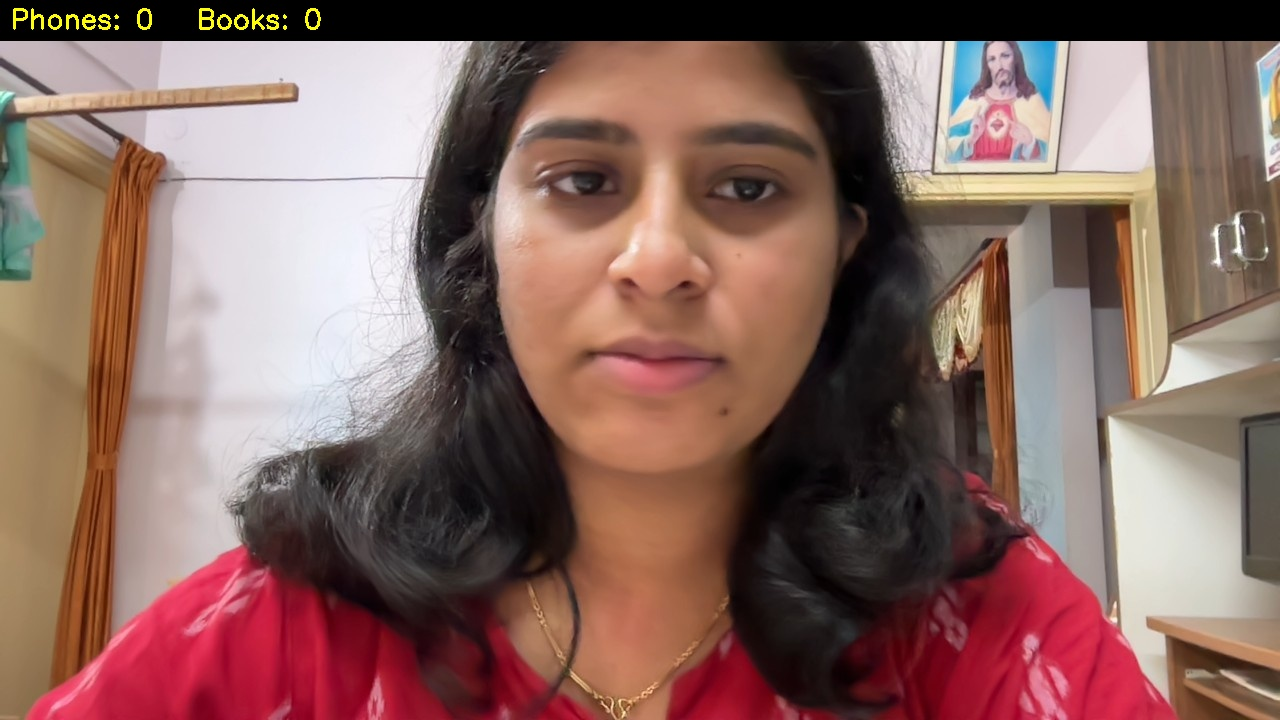

'In view now -> Phones: 0, Books: 0   |   Total appearances -> Phones: 2, Books: 1'

/usr/local/lib/python3.13/dist-packages/yolov5/models/common.py:709: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/usr/local/lib/python3.13/dist-packages/yolov5/models/common.py:709: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/usr/local/lib/python3.13/dist-packages/yolov5/models/common.py:709: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/usr/local/lib/python3.13/dist-packages/yolov5/models/common.py:709: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/usr/local/lib/python3.13/dist-packages/yolov5/models/common.py:709: FutureWarning: `torch.cuda.amp.autocast

Stopped. Totals: {'cell phone': 2, 'book': 1}


In [13]:
import os, csv, time, datetime, base64
import numpy as np, cv2
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js

# ---------- 1. Camera JavaScript (HD frames) ----------
display(Javascript('''
  window.camReady = (async () => {
    const video = document.createElement('video');
    video.style.display = 'none';
    document.body.appendChild(video);
    video.srcObject = await navigator.mediaDevices.getUserMedia(
        {video: {width: 1280, height: 720}});
    await video.play();
    window.camVideo = video;
  })();
  window.getFrame = async () => {
    await window.camReady;
    const v = window.camVideo;
    const c = document.createElement('canvas');
    c.width = v.videoWidth; c.height = v.videoHeight;
    c.getContext('2d').drawImage(v, 0, 0);
    return c.toDataURL('image/jpeg', 0.9);
  };
  window.stopCam = () => window.camVideo.srcObject.getTracks().forEach(t => t.stop());
'''))

# ---------- 2. Logging setup ----------
os.makedirs('snapshots', exist_ok=True)
LOG_FILE = 'detections_log.csv'
if not os.path.exists(LOG_FILE):
    with open(LOG_FILE, 'w', newline='') as f:
        csv.writer(f).writerow(['timestamp', 'class', 'confidence', 'x1', 'y1', 'x2', 'y2'])

COLORS = {'cell phone': (0, 255, 0), 'book': (255, 128, 0)}   # BGR colors
LOG_EVERY = 2.0                      # seconds between CSV writes
last_log = 0
prev_counts = {}
total_seen = {'cell phone': 0, 'book': 0}   # running total of new appearances

# ---------- 3. Drawing ----------
def draw(frame, results):
    counts, rows = {}, []
    for x1, y1, x2, y2, conf, cls in results.xyxy[0].tolist():
        name = model.names[int(cls)]
        counts[name] = counts.get(name, 0) + 1
        color = COLORS.get(name, (0, 255, 0))
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))

        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        label = f'{name} {conf:.2f}'
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(frame, (x1, max(y1 - th - 8, 0)), (x1 + tw + 4, max(y1, th + 8)), color, -1)
        cv2.putText(frame, label, (x1 + 2, max(y1 - 5, th + 3)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
        rows.append((name, round(conf, 3), x1, y1, x2, y2))

    # count banner (black bar with yellow text)
    text = f"Phones: {counts.get('cell phone', 0)}   Books: {counts.get('book', 0)}"
    cv2.rectangle(frame, (0, 0), (frame.shape[1], 40), (0, 0, 0), -1)
    cv2.putText(frame, text, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
    return frame, counts, rows

# ---------- 4. Detection loop ----------
video_handle = display('Starting camera... click Allow in the browser prompt.', display_id=True)
count_handle = display('Counts: waiting...', display_id=True)

try:
    while True:
        data = eval_js('getFrame()')
        frame = cv2.imdecode(np.frombuffer(base64.b64decode(data.split(',')[1]), np.uint8),
                             cv2.IMREAD_COLOR)                                  # BGR
        results = model(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), size=IMG_SIZE)  # model expects RGB
        frame, counts, rows = draw(frame, results)

        now = time.time()
        stamp = datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')

        # log to CSV at most every LOG_EVERY seconds
        if rows and now - last_log >= LOG_EVERY:
            with open(LOG_FILE, 'a', newline='') as f:
                w = csv.writer(f)
                for r in rows:
                    w.writerow([stamp, *r])
            last_log = now

        # snapshot whenever the set of detected objects changes
        if counts and counts != prev_counts:
            cv2.imwrite(f"snapshots/{datetime.datetime.now().strftime('%H%M%S_%f')}.jpg", frame)

        # running totals (must come BEFORE prev_counts is updated)
        for k in total_seen:
            if counts.get(k, 0) > prev_counts.get(k, 0):
                total_seen[k] += counts[k] - prev_counts.get(k, 0)
        prev_counts = counts

        video_handle.update(Image(data=cv2.imencode('.jpg', frame)[1].tobytes()))
        count_handle.update(
            f"In view now -> Phones: {counts.get('cell phone', 0)}, Books: {counts.get('book', 0)}"
            f"   |   Total appearances -> Phones: {total_seen['cell phone']}, Books: {total_seen['book']}")

except KeyboardInterrupt:
    pass
finally:
    try:
        eval_js('stopCam()')
    except Exception:
        pass
    print("Stopped. Totals:", total_seen)

In [14]:
import pandas as pd
df = pd.read_csv('detections_log.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(df.groupby('class')['confidence'].agg(['count', 'mean']).round(2))

df.groupby([df['timestamp'].dt.floor('10s'), 'class']).size().unstack(fill_value=0).plot(
    kind='bar', figsize=(10, 4), title='Detections per 10 seconds')

            count  mean
class                  
book           18  0.46
cell phone     27  0.62


<Axes: title={'center': 'Detections per 10 seconds'}, xlabel='timestamp'>

In [15]:
!zip -rq results.zip snapshots detections_log.csv
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>